# Creating DGPs with PyMC

This notebook builds a DGP object **from scratch on top of the
PyMC library** (`pip install badgers[pymc]`). badgers does not
replace PyMC — it wraps its MCMC machinery into the DGP protocol
so the object plugs into every causal generator. If the bundled
`PyMCDGP` (per-node Bayesian **linear** model) is not enough,
subclass it: PyMC still does the inference, badgers still runs
the graph.

For what an already-fitted DGP can do (sample, intervene,
generator wiring), read `Using-DGPs.ipynb` first. For the protocol
contract (`fit_node`/`response`/`draw_noise`) see
`Create-New-DGP-Using-DowhyGCM.ipynb` — the same three methods
apply here, plus one extra hook.

## The PyMC specifics

`PyMCDGP` keeps the **full posterior**: per node a tiny Bayesian
model (`beta ~ Normal`, `sigma ~ HalfNormal`, Gaussian likelihood)
is fit with MCMC and every draw is stored. `response`/`draw_noise`
on the carrier evaluate draw index 0. Stochastic parameter
selection happens through the hook

```python
pick_parameters(rng)   # called ONCE at the top of each cascade
```

which returns a *pinned view*: an object whose `response`/
`draw_noise` evaluate that one coherent draw, so `sample` and
`intervene` never re-roll parameters mid-graph. Same seed, same
draw.

## The problem: a non-linear mechanism

The bundled backend is linear in the raw parents. On data whose
true mechanism is `Y = 2·sin(X) + noise` it averages over the
wave. The fix: fit on an expanded **feature basis**
(`[p, sin(p)]` per parent) — linear in the basis is non-linear in
the raw parents, and all the posterior machinery survives.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from numpy.random import default_rng

seed = 0
rng = default_rng(seed)

chain = nx.DiGraph([('X', 'Y'), ('Y', 'Z')])
column_mapping = {'X': 0, 'Y': 1, 'Z': 2}

n_samples = 200
Xnl = np.zeros((n_samples, 3))
Xnl[:, 0] = rng.normal(size=n_samples)
Xnl[:, 1] = 2.0 * np.sin(Xnl[:, 0]) + rng.normal(size=n_samples)
Xnl[:, 2] = 0.5 * Xnl[:, 1] * np.abs(Xnl[:, 1]) + rng.normal(size=n_samples)
print(Xnl.shape)

(200, 3)


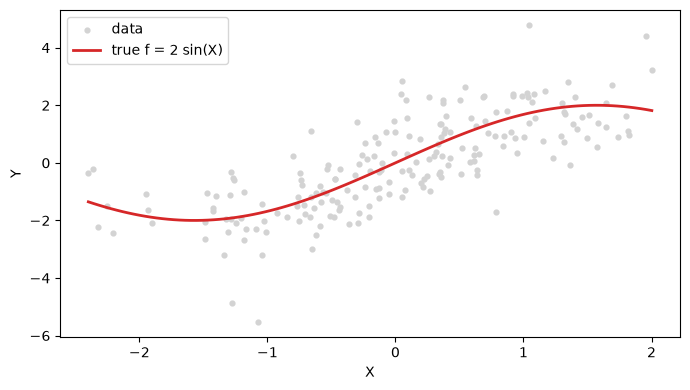

In [2]:
# viz: the non-linear ground truth
grid = np.linspace(Xnl[:, 0].min(), Xnl[:, 0].max(), 100)[:, None]
truth = 2.0 * np.sin(grid).ravel()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(Xnl[:, 0], Xnl[:, 1], s=12, color='lightgray', label='data')
ax.plot(grid, truth, color='C3', lw=2, label='true f = 2 sin(X)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.legend()
plt.tight_layout()

## The subclass: basis features + a matching pinned view

Two overrides:

* `fit_node` builds the basis `Phi` and samples the posterior of
  `beta`/`sigma` on it;
* `pick_parameters` returns a `_PinnedBasisView` — the base
  `_ParameterDrawView` passes **raw** parents to `beta`, so a
  basis-fit beta needs a view that applies the basis first.

In [3]:
import pymc as pm
from badgers.core.dgp.backends.pymc import PyMCDGP, _ParameterDrawView


class _PinnedBasisView(_ParameterDrawView):
    """Pinned posterior draw that evaluates mechanisms THROUGH the
    basis — the carrier's own pinned view would pass raw parents to
    a beta fitted on [p, sin(p)] (shape mismatch)."""

    def response(self, node, parent_values):
        carrier = self._carrier
        if node in carrier._beta:
            return carrier._basis(node, parent_values) @ carrier._beta[node][self._index]
        if node in carrier._mu:
            return np.full(parent_values.shape[0], carrier._mu[node][self._index])
        raise RuntimeError(f"posterior draw has no fitted mechanism for node '{node}'")


class BasisPyMCDGP(PyMCDGP):
    """PyMCDGP on a fixed parent basis: [p, sin(p)] per parent.
    Linear in the basis = non-linear in the raw parents."""

    def _basis(self, node, parent_values):
        return np.column_stack([parent_values, np.sin(parent_values)])

    def fit_node(self, node, parents, data):
        if not parents:
            return super().fit_node(node, parents, data)
        col = self.column_mapping[node]
        mask = np.isfinite(data[:, col])
        for p in parents:
            mask &= np.isfinite(data[:, self.column_mapping[p]])
        d = data[mask]
        if d.shape[0] < len(parents) + 1:
            raise ValueError(f"Cannot fit node '{node}': too few complete rows")
        pcols = [self.column_mapping[p] for p in parents]
        Phi = self._basis(node, d[:, pcols])
        with pm.Model() as model:
            beta_i = pm.Normal('beta', 0, 10, shape=Phi.shape[1])
            sigma_i = pm.HalfNormal('sigma', 1)
            pm.Normal('x', mu=pm.math.dot(Phi, beta_i), sigma=sigma_i,
                      observed=d[:, col])
            trace = pm.sample(draws=self.n_draws,
                              tune=max(self.n_draws // 2, 100),
                              chains=1, cores=1,
                              progressbar=False,
                              compute_convergence_checks=False)
        self._beta[node] = np.asarray(trace.posterior['beta'].values.reshape(self.n_draws, -1))
        self._sigma[node] = np.asarray(trace.posterior['sigma'].values.ravel())

    def response(self, node, parent_values):
        if node in self._beta:
            return self._basis(node, parent_values) @ self._beta[node][0]
        return super().response(node, parent_values)

    def pick_parameters(self, rng=None):
        idx = int(rng.integers(self.n_draws))
        return _PinnedBasisView(self, idx)


bayes_dgp = BasisPyMCDGP(chain, column_mapping, n_draws=200).fit(Xnl)
print('fitted: BasisPyMCDGP (draws:', bayes_dgp.n_draws, ')')

g++ not available, if using conda: `conda install gxx`
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [mu, sigma]
Sampling 1 chain for 100 tune and 200 draw iterations (100 + 200 draws total) took 0 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [beta, sigma]
Sampling 1 chain for 100 tune and 200 draw iterations (100 + 200 draws total) took 0 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [beta, sigma]
Sampling 1 chain for 100 tune and 200 draw iterations (100 + 200 draws total) took 0 seconds.


fitted: BasisPyMCDGP (draws: 200 )


In [4]:
# verify: the posterior-MEAN response tracks the true f
# linear reference: the bundled DowhyGcmDGP
from badgers.core.dgp.backends.dowhy_gcm import DowhyGcmDGP
lin_dgp = DowhyGcmDGP(chain, column_mapping).fit(Xnl)
pred_lin = lin_dgp._anm['Y'].prediction_model.predict(grid).ravel()
rmse_lin = float(np.sqrt(np.mean((pred_lin - truth) ** 2)))

Phi_grid = np.column_stack([grid, np.sin(grid)])
pred = Phi_grid @ bayes_dgp._beta['Y'].mean(axis=0)
rmse = float(np.sqrt(np.mean((pred - truth) ** 2)))
print(f'RMSE vs true f(X) = 2 sin(X): DowhyGcmDGP (linear) {rmse_lin:.3f} '
      f'-> BasisPyMCDGP {rmse:.3f}')

C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RMSE vs true f(X) = 2 sin(X): DowhyGcmDGP (linear) 0.505 -> BasisPyMCDGP 0.090


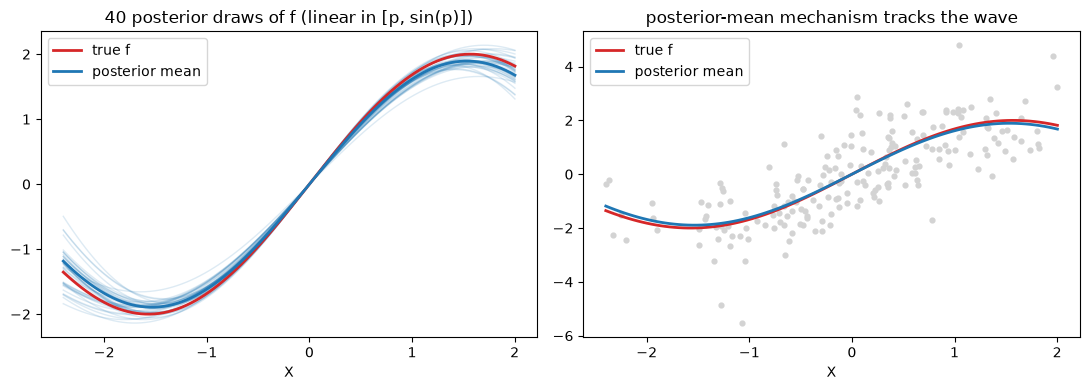

In [5]:
# viz: what the posterior knows about f
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
g = np.linspace(Xnl[:, 0].min(), Xnl[:, 0].max(), 100)
for b in bayes_dgp._beta['Y'][:40]:
    axes[0].plot(g, b[0] * g + b[1] * np.sin(g), color='C0', alpha=0.15, lw=1)
axes[0].plot(g, 2.0 * np.sin(g), color='C3', lw=2, label='true f')
axes[0].plot(g, bayes_dgp._beta['Y'].mean(axis=0)[0] * g
             + bayes_dgp._beta['Y'].mean(axis=0)[1] * np.sin(g),
             color='C0', lw=2, label='posterior mean')
axes[0].set_title('40 posterior draws of f (linear in [p, sin(p)])')
axes[0].set_xlabel('X')
axes[0].legend()

axes[1].plot(g, 2.0 * np.sin(g), color='C3', lw=2, label='true f')
axes[1].plot(g, pred, color='C0', lw=2,
             label='posterior mean')
axes[1].scatter(Xnl[:, 0], Xnl[:, 1], s=12, color='lightgray')
axes[1].set_xlabel('X')
axes[1].set_title('posterior-mean mechanism tracks the wave')
axes[1].legend()
plt.tight_layout()

## Conformance: sampling, pinning, reproducibility

Same checks as any other DGP — plus the pinning asserts that make
the posterior machinery honest.

In [6]:
Xs = bayes_dgp.sample(rng=np.random.default_rng(3), n=2000)
assert np.all(np.isfinite(Xs))
print('marginal means (train vs sampled):',
      np.round(Xnl.mean(axis=0), 2), np.round(Xs.mean(axis=0), 2))

Xi = bayes_dgp.intervene(Xnl.copy(), ['Y'],
                         [np.full(n_samples, 10.0)],
                         rng=np.random.default_rng(4))
assert np.allclose(Xi[:, 1], 10.0)
assert np.allclose(Xi[:, 0], Xnl[:, 0])
print('Z after do(Y=10) ~', np.round(Xi[:, 2].mean(), 1),
      '(theory ~ 50)')

r1 = bayes_dgp.sample(rng=np.random.default_rng(0), n=100)
r2 = bayes_dgp.sample(rng=np.random.default_rng(0), n=100)
r3 = bayes_dgp.sample(rng=np.random.default_rng(1), n=100)
print('same seed -> identical output:', np.allclose(r1, r2))
print('different seed -> different output:', not np.allclose(r2, r3))
assert np.allclose(r1, r2)
assert not np.allclose(r2, r3)

marginal means (train vs sampled): [ 0.02 -0.03 -0.04] [0.01 0.01 0.03]
Z after do(Y=10) ~ 20.6 (theory ~ 50)
same seed -> identical output: True
different seed -> different output: True


## Plugging the custom DGP into a generator

Because the pinned view implements the full protocol, edits and
generator wiring compose through it unchanged.

In [7]:
from badgers.generators.tabular_data.outliers.causal import CausalOutlierPropagationGenerator

gen = CausalOutlierPropagationGenerator(
    random_generator=np.random.default_rng(0), dgp=bayes_dgp)
Xt, y_out = gen.generate(Xnl, y=None, perturbation_nodes=['X'],
                         n_outliers=5)
print('shape:', Xnl.shape, '->', Xt.shape)
print('original rows unchanged:', np.allclose(Xt[:n_samples], Xnl))

shape: (200, 3) -> (205, 3)
original rows unchanged: True


## Takeaways

- badgers wraps PyMC; it does not replace it. A custom DGP on
  PyMC = subclass `PyMCDGP`, override `fit_node` for the model
  you want, keep the stored-draws convention.
- Fit on a feature basis when the mechanism is non-linear in the
  raw parents — linear in the basis is non-linear in the parents.
- Override the pinned view too: the base `_ParameterDrawView`
  evaluates raw parents, not the basis.
- `pick_parameters` is called once per cascade; same seed, same
  coherent draw.